In [1]:
import pandas as pd
from src.io_utils import load_data

sales_list = load_data("data//ecommerce_sales.csv")
df = pd.DataFrame(sales_list)


df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   str    
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 136.8 KB


In [2]:
from src import metrics as M
from src.io_utils import load_data
import matplotlib.pyplot as plt
from src import viz as v

print(f"AOV för hela året är: {M.average_order_value(sales_list):.2f} kr.")
print(f"Medianen för hela året är: {M.calc_median(sales_list)} kr.")



AOV för hela året är: 1401.11 kr.
Medianen för hela året är: 1088.69 kr.


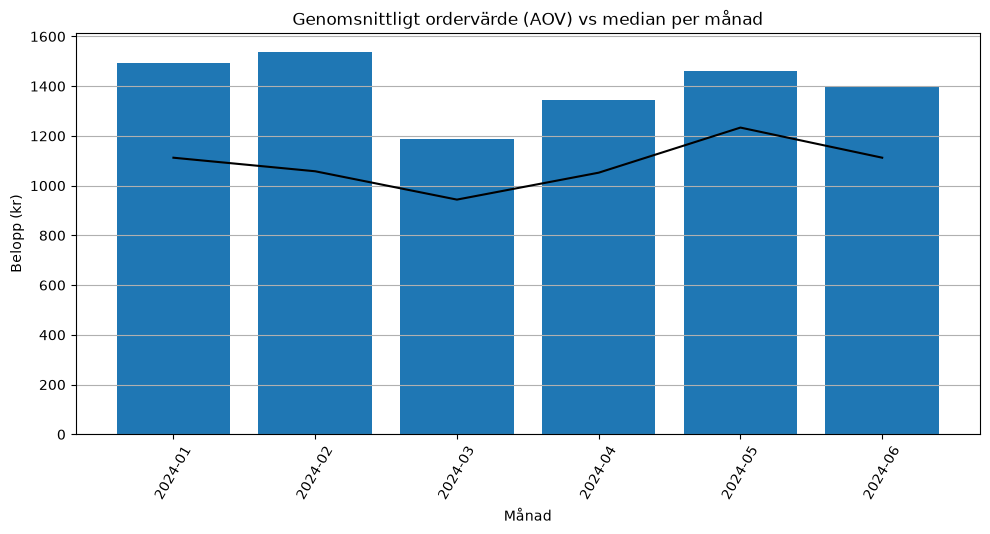

In [3]:
import matplotlib.pyplot as plt
from src import viz as v

df["date"] = pd.to_datetime(df["date"])
monthly_stats = df.groupby(df["date"].dt.to_period("M"))["revenue"].agg(
    ["mean", 
     "median"])

fig, ax = plt.subplots(figsize=(10, 5))
v.plot_monthly_data(ax, monthly_stats)


plt.show()
#v.line(ax, monthly_stats.index.astype(str), monthly_stats["mean"])
#v.line(ax, monthly_stats.index.astype(str), monthly_stats["median"])
